In [101]:
import os
from scipy.interpolate import CubicSpline
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
import copy
import json
from utils.helper import aoa_sim_1_sat_loc, range_estimation

Specify the index of data files, 11 in total (idx = 0-10)

In [102]:
file_idx = 8 # 0-10

Load Starloc configurations

In [103]:
from utils.helper import get_data_configs

data_root_folder = 'data/'

# system parameters                    
fc = 11.325e9                                                       # carrier frequency in Hz
c = 299792458                                                       # speed of light in m/s
lam = c / fc                                                        # wavelength in meters
sample_rate = 2e6                                                   # sample rate (bandwidth) in Hz
d = 13.25e-2                                                        # antenna spacing in meters
stft_win = 14e-3                                                    # STFT window length in seconds
stft_win_len = int(stft_win * sample_rate)                          # STFT window length
f = np.linspace(-sample_rate/2, sample_rate/2, stft_win_len)        # frequency bins for STFT

start_time, date, lat_gt, lon_gt, alt_gt, yaw, pitch, roll = get_data_configs(data_root_folder, file_idx)
# reads data cappture start timestamp in seconds, capture date, Starloc's location latitude (deg), longitude (deg), altitude (m), and Starloc's orientation (yaw, pitch, roll) in degrees
print('Starloc location lat (deg), lon (deg), alt (m): ', lat_gt, lon_gt, alt_gt)

Starloc location lat (deg), lon (deg), alt (m):  40.11614836511319 -88.22277704066285 191.91835843704916


Load satellite signal

In [104]:
%matplotlib inline
data_folder = os.path.join(data_root_folder, date)
tones_dict = sio.loadmat(os.path.join(data_folder, 'tracked_tones.mat'))['tones_dict']
main_tone_dict = sio.loadmat(os.path.join(data_folder, 'tracked_tones.mat'))['main_tone_dict']
id_dict = sio.loadmat(os.path.join(data_folder, 'tracked_tones.mat'))['id_dict']
ref_sig_idx = sio.loadmat(os.path.join(data_folder, 'calibration.mat'))['ref_sig_idx']
phase_offset_01 = sio.loadmat(os.path.join(data_folder, 'calibration.mat'))['phase_offset_01'].T
phase_offset_21 = sio.loadmat(os.path.join(data_folder, 'calibration.mat'))['phase_offset_21'].T
sat_num = len(tones_dict[0, :])

doppler tracking - 9 tones

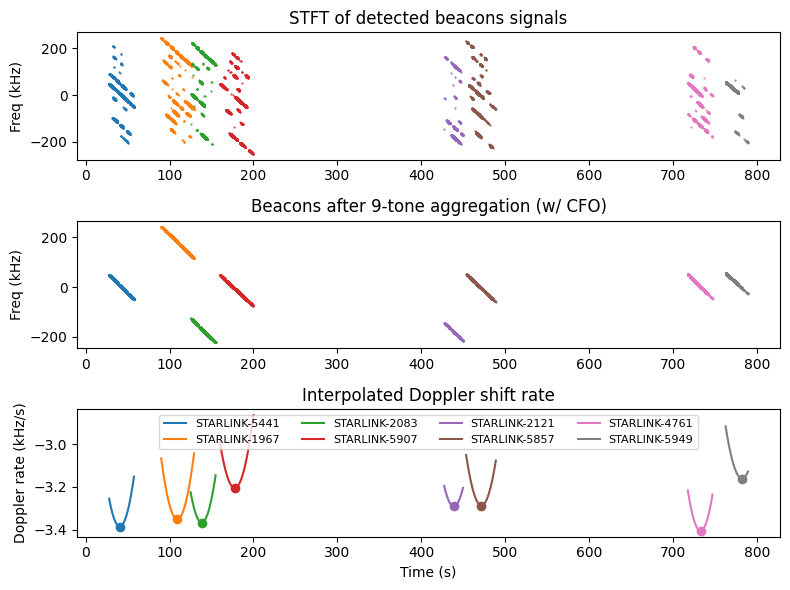

In [105]:
max_el_time_list, dopp_coeff_list = [], []
fig = plt.figure(figsize=(8,6))
for sat_idx in range(sat_num):
    ## 9 tone dopp track 
    tones = tones_dict[0, sat_idx]
    tones_time = tones[:, 0].real # time in seconds
    tones_freq_bin = tones[:, 1].real # frequency bin index
    tones_freq = f[np.array(tones_freq_bin, dtype=int)] # frequency in Hz
    plt.subplot(3, 1, 1)
    plt.plot(tones_time, tones_freq/1e3, '.', markersize=1, label=id_dict[0, sat_idx][0])
    plt.title('STFT of detected beacons signals')
    plt.ylabel('Freq (kHz)')

    # aggregate 9 tones using the prior knowledge that these tones' frequency spacing is 43945.5 Hz
    main_tone = main_tone_dict[0, sat_idx]
    main_tone_time, main_tone_freq = main_tone[:, 0].real, main_tone[:, 1].real
    main_tone_start, main_tone_end = np.min(main_tone_time), np.max(main_tone_time)
    p = np.polyfit(main_tone_time, main_tone_freq, 1)
    tone_freq_spacing = 43945.5 # Hz
    for t_idx in range(len(tones_time)):
        t_i = tones_time[t_idx]
        tones_freq_i = tones_freq[t_idx]
        dopp_i = np.polyval(p, t_i)
        f_offset = tones_freq_i - dopp_i
        n_tones_offset = np.round(f_offset / tone_freq_spacing)
        tones_freq[t_idx] = tones_freq_i - n_tones_offset * tone_freq_spacing
    
    plt.subplot(3, 1, 2)
    plt.plot(tones_time, tones_freq/1e3, '.', markersize=1, label=id_dict[0, sat_idx][0])
    plt.title('Beacons after 9-tone aggregation (w/ CFO)')
    plt.ylabel('Freq (kHz)')

    t_sat_start, t_sat_end = np.min(tones_time), np.max(tones_time)
    p = np.polyfit(tones_time, tones_freq, 3)
    t = np.arange(t_sat_start, t_sat_end, 0.001)
    freqs_polyfit = np.polyval(p, t)/1e3
    freqs_diff = np.diff(freqs_polyfit) / np.diff(t)
    t_diff = t[0:-1] + (t[1]-t[0])/2
    # find the min value of the derivative
    min_idx = np.argmin(freqs_diff)
    if -p[1]/(3*p[0]) < t_sat_start or -p[1]/(3*p[0]) > t_sat_end:
        max_el_time_list.append(t_diff[min_idx])
    else:
        max_el_time_list.append(-p[1]/(3*p[0]))
    dopp_coeff_list.append(p)
    plt.subplot(3, 1, 3)
    plt.plot(t_diff, freqs_diff, label=id_dict[0, sat_idx][0], markersize=2)
    plt.scatter(t_diff[min_idx], freqs_diff[min_idx])
    plt.legend(loc='upper center', ncols=4, fontsize=8)
    plt.title('Interpolated Doppler shift rate')
    plt.xlabel('Time (s)')
    plt.ylabel('Doppler rate (kHz/s)')
    plt.tight_layout()

Simualte ground truth azimuth, elevation, range, phase difference 0-1 and phase difference 1-2

In [106]:
az_gt_list, el_gt_list, range_gt_list, timestamps_list = [], [], [], []  # each list has one entry for each satellite
del_phi_01_gt_list, del_phi_12_gt_list, del_phi_01_polyfit_gt_list, del_phi_12_polyfit_gt_list = [], [], [], []
### Rx antenna locations
rx_loc_1, rx_loc_0, rx_loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])

# get the rotation matrix
R_yaw = np.array([[np.cos(np.deg2rad(yaw)), -np.sin(np.deg2rad(yaw)), 0], [np.sin(np.deg2rad(yaw)), np.cos(np.deg2rad(yaw)), 0], [0, 0, 1]])
R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])
R = R_yaw @ R_pitch @ R_roll

# rotate the rx locations
rx_loc_0, rx_loc_2 = R @ rx_loc_0, R @ rx_loc_2

for sat_idx in range(sat_num):
    ### Get the ground truth del_phi_01 and del_phi_12 using the gt location
    tones = tones_dict[0, sat_idx]
    t_sat_start, t_sat_end = np.min(tones[:, 0].real), np.max(tones[:, 0].real)
    t_sim, az_gt, el_gt, range_gt, sat_loc_gt, _ = aoa_sim_1_sat_loc(data_folder, data_folder+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, lat_gt, lon_gt, alt_gt)
    timestamps = t_sim+t_sat_start

    az_gt, el_gt = np.deg2rad(az_gt), np.deg2rad(el_gt)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    timestamps_list.append(timestamps)

    # considering the gt location as origin, get location of satellite
    loc_sat_wrt_gt = np.array([range_gt*np.cos(el_gt)*np.sin(az_gt), range_gt*np.cos(el_gt)*np.cos(az_gt), range_gt*np.sin(el_gt)]).T

    # get phase difference between the rx antennas given the location of the satellite wrt gt location
    distance_bw_rx0_satloc_gt = np.linalg.norm(loc_sat_wrt_gt - rx_loc_0, axis=1)
    distance_bw_rx1_satloc_gt = np.linalg.norm(loc_sat_wrt_gt - rx_loc_1, axis=1)
    distance_bw_rx2_satloc_gt = np.linalg.norm(loc_sat_wrt_gt - rx_loc_2, axis=1)
    del_phi_01_gt = -2*np.pi*(distance_bw_rx0_satloc_gt - distance_bw_rx1_satloc_gt)/lam
    del_phi_12_gt = -2*np.pi*(distance_bw_rx1_satloc_gt - distance_bw_rx2_satloc_gt)/lam
    p_del_phi_01_gt = np.polyfit(timestamps, del_phi_01_gt, 2)
    p_del_phi_12_gt = np.polyfit(timestamps, del_phi_12_gt, 2)
    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    del_phi_01_polyfit_gt_list.append(p_del_phi_01_gt)
    del_phi_12_polyfit_gt_list.append(p_del_phi_12_gt)

Calculate phase differences and calibrate for orientation and constant phase offset using the first satellite as training data

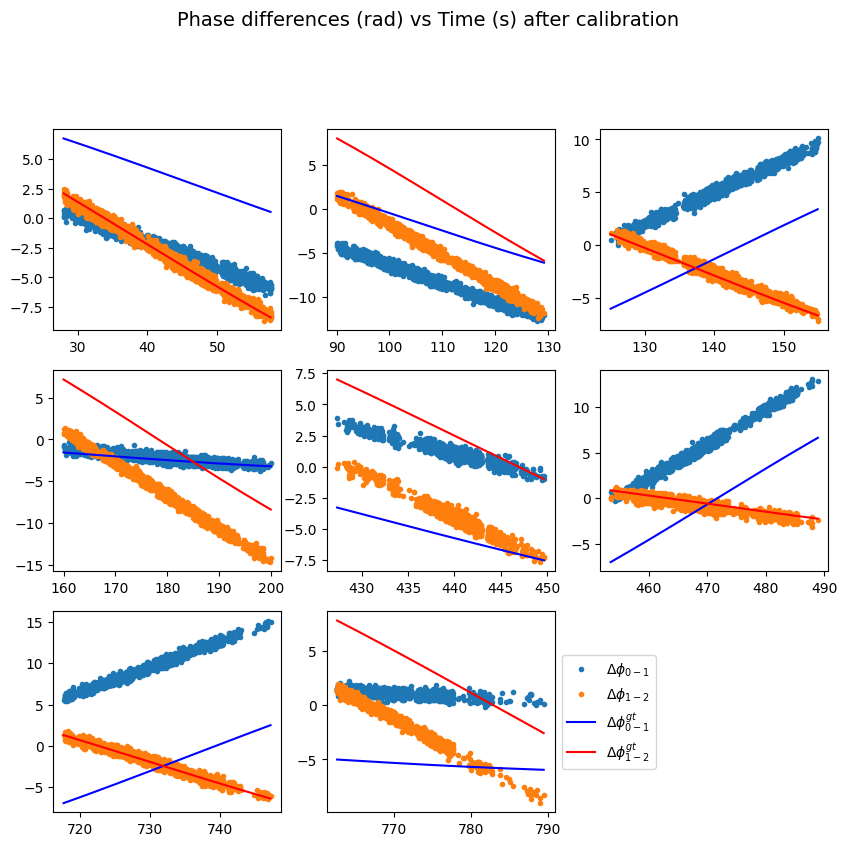

In [107]:
del_phi_01_polycoeff_list, del_phi_12_polycoeff_list = [], []
del_phi_01_list, del_phi_12_list = [], []

# calculate phase differences
for sat_idx in range(sat_num):
    timestamps = timestamps_list[sat_idx]

    tones = tones_dict[0, sat_idx]
    t = tones[:, 0].real
    t_sat_start, t_sat_end = np.min(t), np.max(t)
    phi0 = np.angle(tones[:, 2])
    phi1 = np.angle(tones[:, 3])
    phi2 = np.angle(tones[:, 4])
    del_phi_01 = np.unwrap(phi0 - phi1)
    del_phi_12 = np.unwrap(phi1 - phi2)
    
    # On-wire calibration: compensate phase phase_offset from ref sig
    ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-(t_sat_start+t_sat_end)/2))
    phase_offset_01_ref = phase_offset_01[ref_sig_ii]
    phase_offset_12_ref = -phase_offset_21[ref_sig_ii]
    del_phi_01 -= phase_offset_01_ref
    del_phi_12 -= phase_offset_12_ref
    del_phi_01_list.append(del_phi_01)
    del_phi_12_list.append(del_phi_12)

    p_del_phi_01 = np.polyfit(t, del_phi_01, 2, w = np.minimum(np.abs(tones[:, 2]), np.abs(tones[:, 3])))
    p_del_phi_12 = np.polyfit(t, del_phi_12, 2, w = np.minimum(np.abs(tones[:, 3]), np.abs(tones[:, 4])))
    del_phi_01_polycoeff_list.append(p_del_phi_01)
    del_phi_12_polycoeff_list.append(p_del_phi_12)

# On-air calibration: use the first satellite to compensate for constant phase difference offset
train_sat_idx = 0
gap_01 = np.mean(del_phi_01_gt_list[train_sat_idx] - np.polyval(del_phi_01_polycoeff_list[train_sat_idx], timestamps_list[train_sat_idx]))
gap_12 = np.mean(del_phi_12_gt_list[train_sat_idx] - np.polyval(del_phi_12_polycoeff_list[train_sat_idx], timestamps_list[train_sat_idx]))
gap_01 = (gap_01 + np.pi) % (2 * np.pi) - np.pi # wrap the gap to [-pi, pi]
gap_12 = (gap_12 + np.pi) % (2 * np.pi) - np.pi # wrap the gap to [-pi, pi]
for sat_idx in range(sat_num):
    del_phi_01_list[sat_idx] += gap_01
    del_phi_12_list[sat_idx] += gap_12
    del_phi_01_polycoeff_list[sat_idx][-1] += gap_01
    del_phi_12_polycoeff_list[sat_idx][-1] += gap_12

# Now we can plot the compensated phase differences and compare with gt, they should be offseted by around multiples of 2*pi, which is the ambiguity we need to resolve in the next step
plt.figure(figsize=(10, 12))
plt.suptitle('Phase differences (rad) vs Time (s) after calibration', fontsize=14)
for sat_idx in range(sat_num):
    sat_dopp_track = tones_dict[0, sat_idx]
    t = sat_dopp_track[:, 0].real
    plt.subplot(4,3,sat_idx+1)
    plt.plot(t, del_phi_01_list[sat_idx], '.', label=r'$\Delta\phi_{0-1}$')
    plt.plot(t, del_phi_12_list[sat_idx], '.', label=r'$\Delta\phi_{1-2}$')
    plt.plot(timestamps_list[sat_idx], del_phi_01_gt_list[sat_idx], label=r'$\Delta\phi_{0-1}^{gt}$', color='blue')
    plt.plot(timestamps_list[sat_idx], del_phi_12_gt_list[sat_idx], label=r'$\Delta\phi_{1-2}^{gt}$', color='red')
    if sat_idx == sat_num-1:
        plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

Satellite index:  0
Satellite index:  1
Satellite index:  2
Satellite index:  3
Satellite index:  4
Satellite index:  5
Satellite index:  6
Satellite index:  7


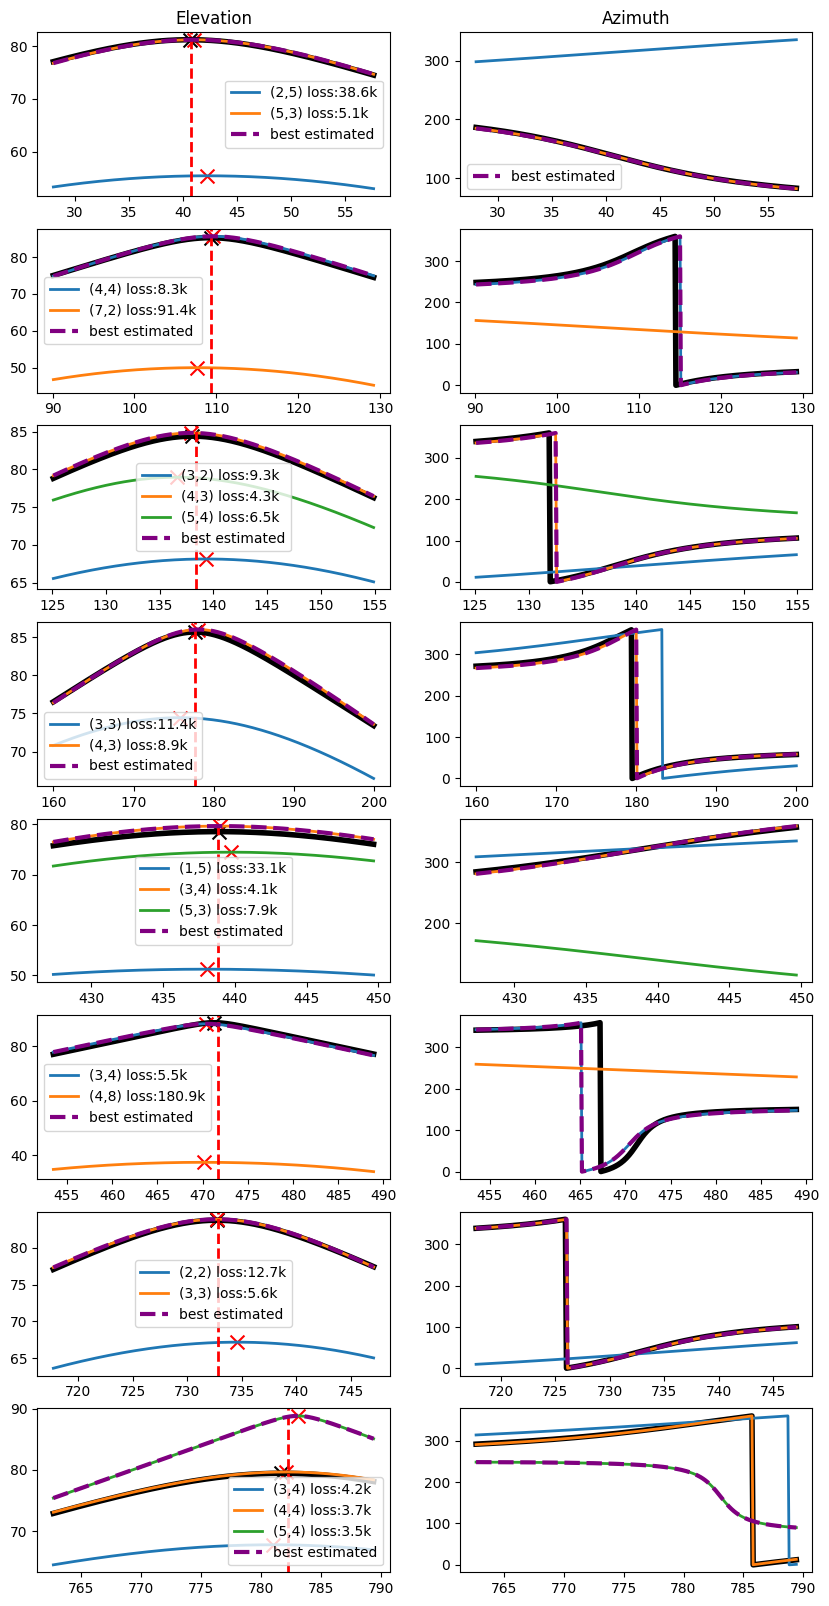

In [108]:
from utils.helper import AoA_orientation_compensation
# calculate az and el from the phase difference
num_ambiguity = int(d/(lam/2))
del_phi_bound = np.pi*num_ambiguity
best_ambiguity = []
orbit_height_est_list = []
best_el_list, best_az_list = [], []

minmum_elevation = 30 # degrees
t_diff_threshold = 2 # seconds

plt.figure(figsize=(10, sat_num*2.5))
fig_idx = 1
for sat_idx in range(sat_num):
    print('Satellite index: ', sat_idx)
    plt.subplot(sat_num, 2, fig_idx)
    plt.plot(timestamps_list[sat_idx], np.rad2deg(el_gt_list[sat_idx]), color='black', linewidth=4)
    plt.scatter(timestamps_list[sat_idx][np.argmax(el_gt_list[sat_idx])], np.rad2deg(el_gt_list[sat_idx][np.argmax(el_gt_list[sat_idx])]), marker='x', color='black', s=100)
    plt.subplot(sat_num, 2, fig_idx+1)
    plt.plot(timestamps_list[sat_idx], np.rad2deg(az_gt_list[sat_idx]), color='black', linewidth=4)
    
    del_phi_01 = np.polyval(del_phi_01_polycoeff_list[sat_idx], timestamps_list[sat_idx])
    del_phi_12 = np.polyval(del_phi_12_polycoeff_list[sat_idx], timestamps_list[sat_idx])

    #get all possible del_phi_01 for sat_idx
    del_phi_01_all = np.zeros((num_ambiguity, len(del_phi_01)))
    ambiguity_vals_01 = np.zeros(num_ambiguity)
    for i in range(num_ambiguity):
        del_phi_01_all[i,:] = del_phi_01 + 2*np.pi*(i-num_ambiguity//2)
        ambiguity_vals_01[i] = 2*np.pi*(i-num_ambiguity//2)
    # get all possible del_phi_12 for sat_idx
    del_phi_12_all = np.zeros((num_ambiguity, len(del_phi_12)))
    ambiguity_vals_12 = np.zeros(num_ambiguity)
    for i in range(num_ambiguity):
        del_phi_12_all[i,:] = del_phi_12 + 2*np.pi*(i-num_ambiguity//2)
        ambiguity_vals_12[i] = 2*np.pi*(i-num_ambiguity//2)
    # only keep valid ambiguity candidates
    del_phi_01_valid_idx = (np.max(del_phi_01_all, axis=1) < del_phi_bound) & (np.min(del_phi_01_all, axis=1) > -del_phi_bound)
    del_phi_12_valid_idx = (np.max(del_phi_12_all, axis=1) < del_phi_bound) & (np.min(del_phi_12_all, axis=1) > -del_phi_bound)
    valid_ambiguity_01 = ambiguity_vals_01[del_phi_01_valid_idx]
    valid_ambiguity_12 = ambiguity_vals_12[del_phi_12_valid_idx]
    del_phi_01_valid = del_phi_01_all[del_phi_01_valid_idx, :]
    del_phi_12_valid = del_phi_12_all[del_phi_12_valid_idx, :]
    
    # calculate doppler rate by fitting a polynomial and taking the derivative, we will use the doppler rate to find the best ambiguity candidate
    dopp_coeff = dopp_coeff_list[sat_idx]
    dopp_curve = np.polyval(dopp_coeff, timestamps_list[sat_idx])
    dopp_rate = np.gradient(dopp_curve, timestamps_list[sat_idx][1]-timestamps_list[sat_idx][0])

    best_amb_01, best_amb_12 = None, None
    best_el, best_az = None, None

    loss_topk, ij_topk, az_topk, el_topk, h_sat_topk = [], [], [], [], []
    for i in range(len(del_phi_01_valid)):
        for j in range(len(del_phi_12_valid)):
            # calculate 2D AoA (azimuth and elevation) from the phase difference
            del_phi_01 = del_phi_01_valid[i]
            del_phi_12 = del_phi_12_valid[j]
            az = np.arctan2(-del_phi_12, -del_phi_01)
            el = np.arccos(np.clip(lam/(2*np.pi*d)*np.sqrt((del_phi_01)**2 + (del_phi_12)**2), -1, 1)) # clip the value to [-1, 1] to avoid nan due to numerical error

            # adjust for yaw pitch roll
            # R_yaw = np.array([[np.cos(np.deg2rad(-yaw)), -np.sin(np.deg2rad(-yaw)), 0], [np.sin(np.deg2rad(-yaw)), np.cos(np.deg2rad(-yaw)), 0], [0, 0, 1]])
            # R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
            # R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])
            # R = R_yaw @ R_pitch @ R_roll
            # x = np.cos(az)*np.cos(el)
            # y = np.sin(az)*np.cos(el)
            # z = np.sin(el)
            # v_local = np.array([x, y, z]).T
            # v_global = np.dot(R, v_local.T).T
            # az = np.arctan2(v_global[:,1], v_global[:,0])
            # az = np.mod(az, 2*np.pi)
            # el = np.arcsin(v_global[:,2])
            az, el = AoA_orientation_compensation(az, el, yaw, pitch, roll)

            if np.any(np.isnan(el)) or np.nanmin(np.rad2deg(el)) < minmum_elevation:
                continue
            t_el_max = timestamps_list[sat_idx][np.argmax(el)]
            if np.abs(max_el_time_list[sat_idx] - t_el_max) > t_diff_threshold:
                continue

            h_sat, v_sat = range_estimation(start_time, 500e3, 600e3, 1e3, np.rad2deg(el), np.rad2deg(az), timestamps_list[sat_idx], lat_gt, lon_gt, alt_gt)
            R_earth = 6371e3  # Earth's radius in meters
            R_sat = R_earth + h_sat
            rho = -R_earth * np.sin(el) + np.sqrt(R_sat**2 - (R_earth**2) * (np.cos(el)**2))
            rho_dot = np.gradient(rho, timestamps_list[sat_idx][1]-timestamps_list[sat_idx][0])
            doppler_est = - (fc / c) * rho_dot  # Doppler shift estimation
            doppler_rate_est = np.gradient(doppler_est, timestamps_list[sat_idx][1]-timestamps_list[sat_idx][0]) # Doppler rate estimation

            kk = 3 # number of candidates to visulize
            loss_ij = np.linalg.norm(dopp_rate-doppler_rate_est)
            if len(loss_topk) < kk or loss_ij < np.max(loss_topk):
                if len(loss_topk) == kk:
                    max_loss_idx = np.argmax(loss_topk)
                    loss_topk.pop(max_loss_idx)
                    ij_topk.pop(max_loss_idx)
                    az_topk.pop(max_loss_idx)
                    el_topk.pop(max_loss_idx)
                    h_sat_topk.pop(max_loss_idx)
                az_topk.append(az)
                el_topk.append(el)
                loss_topk.append(loss_ij)
                ij_topk.append((i,j))
                h_sat_topk.append(h_sat)

    min_loss = np.inf
    for idx in range(len(loss_topk)):
        i, j = ij_topk[idx]
        el = el_topk[idx]
        az = az_topk[idx]
        h_sat = h_sat_topk[idx]
        el_max_idx = np.argmax(el)
        t_el_max = timestamps_list[sat_idx][el_max_idx]

        plt.subplot(sat_num, 2, fig_idx)
        plt.plot(timestamps_list[sat_idx], np.rad2deg(el), label=f"({i},{j}) loss:{loss_topk[idx]/1000:.1f}k", linewidth=2)
        plt.scatter(t_el_max, np.rad2deg(el[el_max_idx]), marker='x', color='red', s=100)
        plt.subplot(sat_num, 2, fig_idx+1)
        plt.plot(timestamps_list[sat_idx], np.rad2deg(az), linewidth=2)
        
        # find the best one based on loss
        if loss_topk[idx] < min_loss:
            min_loss = loss_topk[idx]
            best_amb_01, best_amb_12 = valid_ambiguity_01[i], valid_ambiguity_12[j]
            best_el, best_az = el, az
            best_h_sat = h_sat
    best_ambiguity.append((best_amb_01, best_amb_12))
    orbit_height_est_list.append(best_h_sat)
    best_el_list.append(best_el)
    best_az_list.append(best_az)
    
    plt.subplot(sat_num, 2, fig_idx)
    plt.axvline(x=max_el_time_list[sat_idx], color='red', linestyle='--', linewidth=2)
    plt.plot(timestamps_list[sat_idx], np.rad2deg(best_el), '--', label="best estimated", color='purple', linewidth=3)

    if sat_idx == 0:
        plt.title("Elevation")
    plt.legend()
    plt.subplot(sat_num, 2, fig_idx+1)
    plt.plot(timestamps_list[sat_idx], np.rad2deg(best_az), '--', label="best estimated", color='purple', linewidth=3)
    if sat_idx == 0:
        plt.title("Azimuth")
        plt.legend() 
    fig_idx += 2



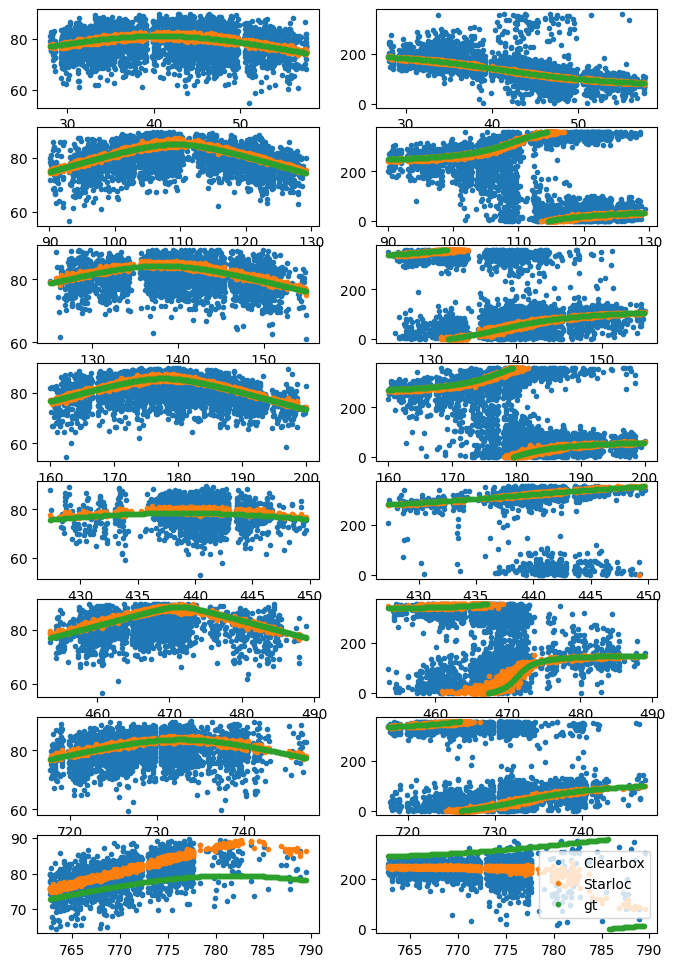

In [109]:

# generate baseline
el_baseline_list, az_baseline_list = [], []
pointing_err_list, pointing_err_baseline_list = [], []
az_starloc_list, el_starloc_list = [], []
plt.figure(figsize=(8,12))
fig_idx = 1
az_gt_origphase_list, el_gt_origphase_list, range_gt_origphase_list = [], [], []

for sat_idx in range(sat_num):
    tones = tones_dict[0, sat_idx]
    t = tones[:, 0].real

    # Starloc
    del_phi_01_best = del_phi_01_list[sat_idx]+best_ambiguity[sat_idx][0]
    del_phi_12_best = del_phi_12_list[sat_idx]+best_ambiguity[sat_idx][1]
    az_starloc = np.arctan2(-del_phi_12_best, -del_phi_01_best)
    el_starloc = np.arccos(np.clip(lam/(2*np.pi*d)*np.sqrt((del_phi_01_best)**2 + (del_phi_12_best)**2), -1, 1)) # clip the value to [-1, 1] to avoid nan due to numerical error

    # adjust for yaw pitch roll
    # x = np.cos(az_starloc)*np.cos(el_starloc)
    # y = np.sin(az_starloc)*np.cos(el_starloc)
    # z = np.sin(el_starloc)
    # v_local = np.array([x, y, z]).T
    # v_global = np.dot(R, v_local.T).T
    # x, y, z = v_global[:,0], v_global[:,1], v_global[:,2]
    # az_starloc = np.arctan2(v_global[:,1], v_global[:,0])
    # az_starloc = np.mod(az_starloc, 2*np.pi)
    # el_starloc = np.arcsin(v_global[:,2])
    az_starloc, el_starloc = AoA_orientation_compensation(az_starloc, el_starloc, yaw, pitch, roll)
    az_starloc_list.append(az_starloc)
    el_starloc_list.append(el_starloc)

    # baseline
    coeff_01_t = np.polyfit(t, del_phi_01_best, 2)
    coeff_12_t = np.polyfit(t, del_phi_12_best, 2)
    del_phi_01_baseline = np.polyval(coeff_01_t, t) / num_ambiguity
    del_phi_12_baseline = np.polyval(coeff_12_t, t) / num_ambiguity
    for i in range(len(del_phi_01_baseline)):
        t_i = t[i]
        noise_01 = del_phi_01_best[i] - np.polyval(coeff_01_t, t_i)
        noise_12 = del_phi_12_best[i] - np.polyval(coeff_12_t, t_i)
        del_phi_01_baseline[i] = del_phi_01_baseline[i] + noise_01
        del_phi_12_baseline[i] = del_phi_12_baseline[i] + noise_12
        # make sure they are within -pi to pi
        while np.abs(del_phi_01_baseline[i]) > np.pi:
            del_phi_01_baseline[i] = del_phi_01_baseline[i] - np.sign(del_phi_01_baseline[i])*2*np.pi
        while np.abs(del_phi_12_baseline[i]) > np.pi:
            del_phi_12_baseline[i] = del_phi_12_baseline[i] - np.sign(del_phi_12_baseline[i])*2*np.pi
    az_baseline = np.arctan2(-del_phi_12_baseline, -del_phi_01_baseline)
    el_baseline = np.arccos(np.clip(lam/(2*np.pi*(d / num_ambiguity))*np.sqrt((del_phi_01_baseline)**2 + (del_phi_12_baseline)**2), -1, 1)) # clip the value to [-1, 1] to avoid nan due to numerical error
    
    # adjust for yaw pitch roll
    # x_baseline = np.cos(az_baseline)*np.cos(el_baseline)
    # y_baseline = np.sin(az_baseline)*np.cos(el_baseline)
    # z_baseline = np.sin(el_baseline)
    # v_local_baseline = np.array([x_baseline, y_baseline, z_baseline]).T
    # v_global_baseline = np.dot(R, v_local_baseline.T).T
    # x_baseline, y_baseline, z_baseline = v_global_baseline[:,0], v_global_baseline[:,1], v_global_baseline[:,2]
    # az_baseline = np.arctan2(v_global_baseline[:,1], v_global_baseline[:,0])
    # az_baseline = np.mod(az_baseline, 2*np.pi)
    # el_baseline = np.arcsin(v_global_baseline[:,2])
    az_baseline, el_baseline = AoA_orientation_compensation(az_baseline, el_baseline, yaw, pitch, roll)
    el_baseline_list.append(el_baseline)
    az_baseline_list.append(az_baseline)

    # ground truth
    coeff_01_gt = np.polyfit(timestamps_list[sat_idx], del_phi_01_gt_list[sat_idx], 2)
    coeff_12_gt = np.polyfit(timestamps_list[sat_idx], del_phi_12_gt_list[sat_idx], 2)
    az_gt = np.arctan2(-np.polyval(coeff_12_gt, t), -np.polyval(coeff_01_gt, t))
    el_gt = np.arccos(np.clip(lam/(2*np.pi*d)*np.sqrt(np.polyval(coeff_01_gt, t)**2 + np.polyval(coeff_12_gt, t)**2), -1, 1))
    az_gt_origphase_list.append(az_gt)
    el_gt_origphase_list.append(el_gt)
    range_gt = range_gt_list[sat_idx]
    cs = CubicSpline(timestamps_list[sat_idx], range_gt)
    range_gt_upsampled = cs(t)
    range_gt_origphase_list.append(range_gt_upsampled)

    x_gt = np.cos(az_gt)*np.cos(el_gt)
    y_gt = np.sin(az_gt)*np.cos(el_gt)
    z_gt = np.sin(el_gt)
    x, y, z = np.cos(az_starloc)*np.cos(el_starloc), np.sin(az_starloc)*np.cos(el_starloc), np.sin(el_starloc)
    v = np.array([x, y, z]).T
    x_baseline, y_baseline, z_baseline = np.cos(az_baseline)*np.cos(el_baseline), np.sin(az_baseline)*np.cos(el_baseline), np.sin(el_baseline)
    v_baseline = np.array([x_baseline, y_baseline, z_baseline]).T
    v_gt = np.array([x_gt, y_gt, z_gt]).T
    dot_prods = np.sum(v*v_gt, axis=1)
    dot_prods_baseline = np.sum(v_baseline*v_gt, axis=1)
    norms1 = np.linalg.norm(v, axis=1)
    norms2 = np.linalg.norm(v_gt, axis=1)
    norms3 = np.linalg.norm(v_baseline, axis=1)
    cosines = dot_prods/(norms1*norms2)
    cosines_baseline = dot_prods_baseline/(norms3*norms2)
    pointing_error_angle = np.arccos(cosines)
    pointing_err_list.append(pointing_error_angle)
    pointing_error_angle_baseline = np.arccos(cosines_baseline)
    pointing_err_baseline_list.append(pointing_error_angle_baseline)

    plt.subplot(sat_num, 2, fig_idx)
    plt.plot(t, np.rad2deg(el_baseline), '.', label='Clearbox')
    plt.plot(t, np.rad2deg(el_starloc), '.', label='Starloc')
    plt.plot(timestamps_list[sat_idx], np.rad2deg(el_gt_list[sat_idx]), '.', label='gt')
    plt.subplot(sat_num, 2, fig_idx+1)
    plt.plot(t, np.rad2deg(az_baseline), '.', label='Clearbox')
    plt.plot(t, np.rad2deg(az_starloc), '.', label='Starloc')
    plt.plot(timestamps_list[sat_idx], np.rad2deg(az_gt_list[sat_idx]), '.', label='gt')
    fig_idx += 2

plt.legend()
plt.show()

In [110]:
# save data
res_folder = 'results/'
dict_res = {}
dict_res_baseline = {}
for sat_idx in range(sat_num):
    best_az_i = az_starloc_list[sat_idx]
    best_el_i = el_starloc_list[sat_idx]
    az_i_baseline = az_baseline_list[sat_idx]
    el_i_baseline = el_baseline_list[sat_idx]
    pointing_err = pointing_err_list[sat_idx]
    pointing_err_baseline = pointing_err_baseline_list[sat_idx]
    az_gt_origphase = az_gt_origphase_list[sat_idx]
    el_gt_origphase = el_gt_origphase_list[sat_idx]
    range_gt_origphase = range_gt_origphase_list[sat_idx]
    orbit_height_est = orbit_height_est_list[sat_idx]
    orbit_hight_gt = range_gt_origphase[np.argmax(el_gt_origphase)] * np.sin(el_gt_origphase[np.argmax(el_gt_origphase)])
    dict_res[sat_idx] = {'orbit_height_gt': orbit_hight_gt.item(), 'orbit_height_est': orbit_height_est.item(), 'range_gt_origphase': range_gt_origphase.tolist(), 'az_origphase': best_az_i.tolist(), 'el_origphase': best_el_i.tolist(), 'az_baseline_origphase': az_i_baseline.tolist(), 'el_baseline_origphase': el_i_baseline.tolist(), 'pointing_err_origphase': pointing_err.tolist(), 'pointing_err_baseline_origphase': pointing_err_baseline.tolist(), 'az_gt_origphase': az_gt_origphase.tolist(), 'el_gt_origphase': el_gt_origphase.tolist()}

starloc_config = {'date': date, 'lat_gt': lat_gt, 'lon_gt': lon_gt, 'alt_gt': alt_gt, 'sat_num': sat_num, 'train_num': 1}
dict_res['__starloc_config__'] = starloc_config
with open(os.path.join(res_folder, date+'.json'), 'w') as f:
    json.dump(dict_res, f)